# 05. K-code 원본 ROI 각인 보존도 측정

학습 데이터 (K-code 원본, 누끼 전) ROI 에서 각인 보존도를 측정한다.

## 배경

단계 2-B (`03_imprint_visibility.ipynb`) 는 `crops_cache.pkl` 의 누끼 처리된 합성용 ROI 100개를 측정. 본 노트북은 동일 측정 방법을 K-code 원본 (누끼 전) 에 적용.

## 측정 항목

1. K-code 원본 ROI 각인 강도 분포 — imprint 픽셀 비율 / mean Laplacian
2. rembg 누끼 처리 전후 각인 보존 비교 (누끼 자체의 손실 분리)
3. K-code 원본 ROI imgsz 다운샘플 시 각인 보존 (M2 방법, 단계 2-B 와 동일)
4. (부수) 단계 2-C 에서 발견한 GT 매칭 의심 8개 박스 시각 검증

---

*작성일: 2026-05-02 / 단계 2-D*

## 0. 셋업 + 자료구조 진단

K-code 원본 데이터가 로컬 어디에 어떤 가공본으로 존재하는지 확인. 측정 시작 전 자료구조부터 출력 (협업 원칙 59).

확인할 것:
- crops_cache 자료구조 재확인
- ROOT 하위 디렉토리 트리
- 평가 JSON / 33장 테스트셋 경로

In [1]:
## 셀 1 — 셋업 + 경로/자료구조 진단 (측정 코드 없음)

from pathlib import Path
import pickle
import json
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ── 경로 ──
ROOT = Path(r"D:\pill_detection")
ANALYSIS_DIR = ROOT / "analysis"
FIG_DIR = ANALYSIS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CACHE_PATH = ROOT / "crops_cache.pkl"
EVAL_JSON = ROOT / "eval" / "rtmdet_tiny_synth_e15_seed100_results.json"


# ── 한글 폰트 ──
candidates = ['Malgun Gothic', 'NanumGothic', 'Gulim']
available = {f.name for f in fm.fontManager.ttflist}
for name in candidates:
    if name in available:
        plt.rcParams['font.family'] = name
        print(f"한글 폰트: {name}")
        break
plt.rcParams['axes.unicode_minus'] = False


# ── 헬퍼 ──
def imread_kr(path):
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)


# ============================================================
# 1) crops_cache 자료구조 재확인 (단계 2-B 와 동일하지만 새 노트북이니 재출력)
# ============================================================
print("\n" + "=" * 60)
print("[1] crops_cache.pkl 자료구조")
print("=" * 60)
with open(CACHE_PATH, "rb") as f:
    crops = pickle.load(f)

print(f"타입: {type(crops).__name__}, 길이: {len(crops)}")
sample = crops[0] if not isinstance(crops, dict) else next(iter(crops.values()))
print(f"항목 키: {list(sample.keys())}")
img_obj = sample['img']
print(f"img 타입: {type(img_obj).__name__}")
if hasattr(img_obj, 'mode'):
    print(f"  PIL mode: {img_obj.mode}, size(W×H): {img_obj.size}")
print(f"기타 키 예시: w={sample['w']}, h={sample['h']}, "
      f"class_idx={sample.get('class_idx', '키없음')}")


# ============================================================
# 2) K-code 원본 데이터 위치 탐색 — D:\pill_detection\ 하위
# ============================================================
print("\n" + "=" * 60)
print("[2] K-code 원본 데이터 위치 후보 탐색")
print("=" * 60)
print("ROOT 하위 1단계 디렉토리/파일:")
for p in sorted(ROOT.iterdir()):
    if p.is_dir():
        n_items = len(list(p.iterdir())) if p.exists() else 0
        print(f"  [DIR]  {p.name}/  ({n_items}개)")
    else:
        size_mb = p.stat().st_size / 1024 / 1024
        print(f"  [FILE] {p.name}  ({size_mb:.1f} MB)")


# data 디렉토리가 있다면 한 단계 더
DATA_DIR = ROOT / "data"
if DATA_DIR.exists():
    print(f"\n{DATA_DIR}/ 하위:")
    for p in sorted(DATA_DIR.iterdir()):
        if p.is_dir():
            n = len(list(p.iterdir()))
            print(f"  [DIR]  {p.name}/  ({n}개)")
        else:
            print(f"  [FILE] {p.name}")


# ============================================================
# 3) 평가 JSON 존재 확인 (단계 2-C 재사용)
# ============================================================
print("\n" + "=" * 60)
print("[3] 평가 JSON 확인")
print("=" * 60)
print(f"경로: {EVAL_JSON}")
print(f"존재: {EVAL_JSON.exists()}")
if EVAL_JSON.exists():
    print(f"크기: {EVAL_JSON.stat().st_size / 1024:.1f} KB")
    with open(EVAL_JSON, "r", encoding="utf-8") as f:
        eval_data = json.load(f)
    print(f"최상위 키: {list(eval_data.keys())}")
    print(f"results 길이: {len(eval_data['results'])}")


# ============================================================
# 4) 테스트 이미지/라벨 확인
# ============================================================
print("\n" + "=" * 60)
print("[4] 33장 테스트셋 경로 확인")
print("=" * 60)
TEST_IMG_DIR = ROOT / "eval" / "test_images"
TEST_LBL_DIR = ROOT / "eval" / "test_labels" / "test_labels"
print(f"이미지 디렉토리 존재: {TEST_IMG_DIR.exists()}, "
      f"파일수: {len(list(TEST_IMG_DIR.glob('*'))) if TEST_IMG_DIR.exists() else 0}")
print(f"라벨 디렉토리 존재: {TEST_LBL_DIR.exists()}, "
      f"파일수: {len(list(TEST_LBL_DIR.glob('*'))) if TEST_LBL_DIR.exists() else 0}")

한글 폰트: Malgun Gothic

[1] crops_cache.pkl 자료구조
타입: list, 길이: 7503
항목 키: ['img', 'class_idx', 'w', 'h']
img 타입: Image
  PIL mode: RGBA, size(W×H): (169, 165)
기타 키 예시: w=169, h=165, class_idx=8

[2] K-code 원본 데이터 위치 후보 탐색
ROOT 하위 1단계 디렉토리/파일:
  [DIR]  .claude/  (2개)
  [DIR]  .git/  (13개)
  [FILE] .gitignore  (0.0 MB)
  [DIR]  _toolkit/  (10개)
  [DIR]  analysis/  (7개)
  [FILE] CLAUDE.md  (0.0 MB)
  [FILE] crops_cache.pkl  (2573.9 MB)
  [FILE] dark_surface_backgrounds.zip  (11.3 MB)
  [DIR]  data/  (28개)
  [DIR]  demo/  (6개)
  [DIR]  eda/  (18개)
  [DIR]  eval/  (17개)
  [FILE] generate_dark_surface.ipynb  (3.1 MB)
  [FILE] kaggle_test_images.zip  (1447.0 MB)
  [DIR]  kaggle_upload/  (4개)
  [FILE] pexels_collector.py  (0.0 MB)
  [FILE] README.md  (0.0 MB)
  [FILE] requirements-all.txt  (0.0 MB)
  [FILE] requirements-eda.txt  (0.0 MB)
  [FILE] requirements-rtmdet.txt  (0.0 MB)
  [FILE] requirements-train.txt  (0.0 MB)
  [DIR]  results/  (9개)
  [FILE] rtmdet_demo_package.zip  (39.1 MB)
  [DIR]

## 1. K-code 원본 데이터 위치 후보 탐색

`data/` 하위에 후보 디렉토리 다수 (`TL_*_조합`, `TS_*_조합`, `train_images`, `kaggle_images`, `dataset_yolo`, `team_preprocessed`). 각 후보가 무엇이고 어디서 K-code ROI 를 가장 깔끔하게 추출할 수 있는지 직접 출력으로 확정.

In [2]:
## 셀 2 — K-code 원본 데이터 후보 깊이 탐색 (출력만, 측정 없음)

# ============================================================
# 1) TL_4_조합 폴더 내부 구조 (3 단계 깊이)
# ============================================================
TL4 = ROOT / "data" / "TL_4_조합"
print(f"[1] {TL4.name}/ 내부")
print("=" * 60)

items_l1 = sorted(TL4.iterdir())
print(f"총 항목: {len(items_l1)}")
print(f"처음 5개:")
for p in items_l1[:5]:
    if p.is_dir():
        n = len(list(p.iterdir()))
        print(f"  [DIR]  {p.name}/  ({n}개)")
    else:
        print(f"  [FILE] {p.name}  ({p.stat().st_size / 1024:.1f} KB)")


# 첫 하위 폴더 깊이 1 단계 더
first_subdir = next((p for p in items_l1 if p.is_dir()), None)
if first_subdir:
    print(f"\n  [{first_subdir.name}/] 하위:")
    sub_items = sorted(first_subdir.iterdir())
    print(f"    총 항목: {len(sub_items)}")
    for p in sub_items[:8]:
        if p.is_dir():
            n_inner = len(list(p.iterdir()))
            print(f"    [DIR]  {p.name}/  ({n_inner}개)")
        else:
            size_kb = p.stat().st_size / 1024
            print(f"    [FILE] {p.name}  ({size_kb:.1f} KB)")
    
    # 한 단계 더
    first_inner = next((p for p in sub_items if p.is_dir()), None)
    if first_inner:
        print(f"\n    [{first_inner.name}/] 하위:")
        inner_items = sorted(first_inner.iterdir())[:8]
        for p in inner_items:
            size_kb = p.stat().st_size / 1024 if p.is_file() else 0
            tag = '[DIR]' if p.is_dir() else '[FILE]'
            print(f"      {tag} {p.name}  ({size_kb:.1f} KB)" if p.is_file() else f"      {tag} {p.name}/")


# ============================================================
# 2) train_images / train_annotations 샘플
# ============================================================
print("\n" + "=" * 60)
print("[2] train_images / train_annotations 샘플")
print("=" * 60)

TRAIN_IMG = ROOT / "data" / "train_images"
TRAIN_ANN = ROOT / "data" / "train_annotations"

if TRAIN_IMG.exists():
    files = sorted(TRAIN_IMG.iterdir())
    exts = set(p.suffix for p in files)
    print(f"\ntrain_images: {len(files)}개, 확장자: {exts}")
    print(f"  예시 3개: {[p.name for p in files[:3]]}")
    # 한 파일 크기 확인
    if files:
        sample_img = imread_kr(files[0])
        if sample_img is not None:
            print(f"  첫 이미지 shape: {sample_img.shape}")

if TRAIN_ANN.exists():
    files = sorted(TRAIN_ANN.iterdir())
    exts = set(p.suffix for p in files)
    print(f"\ntrain_annotations: {len(files)}개, 확장자: {exts}")
    print(f"  예시 3개: {[p.name for p in files[:3]]}")
    
    # 한 파일 내용 확인
    if files:
        first_ann = files[0]
        if first_ann.suffix == '.json':
            with open(first_ann, 'r', encoding='utf-8') as f:
                ann_sample = json.load(f)
            print(f"\n  {first_ann.name} 최상위 타입: {type(ann_sample).__name__}")
            if isinstance(ann_sample, dict):
                print(f"  키: {list(ann_sample.keys())}")
            elif isinstance(ann_sample, list):
                print(f"  길이: {len(ann_sample)}")
                if ann_sample and isinstance(ann_sample[0], dict):
                    print(f"  [0] 키: {list(ann_sample[0].keys())}")


# ============================================================
# 3) merged_train_after_category_merge.csv 헤더 / 일부
# ============================================================
print("\n" + "=" * 60)
print("[3] merged_train_after_category_merge.csv")
print("=" * 60)

CSV_PATH = ROOT / "data" / "merged_train_after_category_merge.csv"
if CSV_PATH.exists():
    df_merged = pd.read_csv(CSV_PATH)
    print(f"shape: {df_merged.shape}")
    print(f"columns: {list(df_merged.columns)}")
    print(f"\n첫 3행:")
    print(df_merged.head(3).to_string())


# ============================================================
# 4) team_preprocessed / dataset_yolo 디렉토리 (가공본인지 원본 보강인지)
# ============================================================
print("\n" + "=" * 60)
print("[4] team_preprocessed / dataset_yolo 구조")
print("=" * 60)

for name in ["team_preprocessed", "dataset_yolo"]:
    d = ROOT / "data" / name
    if d.exists():
        print(f"\n{name}/:")
        for p in sorted(d.iterdir()):
            if p.is_dir():
                n = len(list(p.iterdir()))
                print(f"  [DIR]  {p.name}/  ({n}개)")
            else:
                size_mb = p.stat().st_size / 1024 / 1024
                print(f"  [FILE] {p.name}  ({size_mb:.1f} MB)")

[1] TL_4_조합/ 내부
총 항목: 500
처음 5개:
  [DIR]  K-004378-005002-005094-019552_json/  (4개)
  [DIR]  K-004378-005002-005094-022627_json/  (4개)
  [DIR]  K-004378-005002-005094-023223_json/  (4개)
  [DIR]  K-004378-005002-006192-025438_json/  (4개)
  [DIR]  K-004378-005002-012778-025438_json/  (4개)

  [K-004378-005002-005094-019552_json/] 하위:
    총 항목: 4
    [DIR]  K-004378/  (3개)
    [DIR]  K-005002/  (3개)
    [DIR]  K-005094/  (3개)
    [DIR]  K-019552/  (3개)

    [K-004378/] 하위:
      [FILE] K-004378-005002-005094-019552_0_2_0_2_70_000_200.json  (1.9 KB)
      [FILE] K-004378-005002-005094-019552_0_2_0_2_75_000_200.json  (1.9 KB)
      [FILE] K-004378-005002-005094-019552_0_2_0_2_90_000_200.json  (1.9 KB)

[2] train_images / train_annotations 샘플

train_images: 232개, 확장자: {'.png'}
  예시 3개: ['K-001900-016548-019607-029451_0_2_0_2_70_000_200.png', 'K-001900-016548-019607-029451_0_2_0_2_75_000_200.png', 'K-001900-016548-019607-029451_0_2_0_2_90_000_200.png']
  첫 이미지 shape: (1280, 976, 3)

train_anno

C:\Users\tran6\AppData\Local\Temp\ipykernel_7136\1626352350.py:97: DtypeWarning: Columns (38) have mixed types. Specify dtype option on import or set low_memory=False.
  df_merged = pd.read_csv(CSV_PATH)


shape: (40844, 45)
columns: ['file_name', 'image_id', 'width', 'height', 'category_id', 'dl_name', 'dl_name_en', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h', 'area', 'color_class1', 'color_class2', 'drug_shape', 'print_front', 'print_back', 'form_code_name', 'di_etc_otc_code', 'camera_la', 'leng_long', 'leng_short', 'thick', 'class_idx', 'class_name', 'bbox_cx', 'bbox_cy', 'bbox_cx_n', 'bbox_cy_n', 'bbox_w_n', 'bbox_h_n', 'back_color', 'di_class_no', 'dl_company', 'dl_idx', 'dl_mapping_code', 'dl_material', 'drug_dir', 'image_exists', 'json_path', 'light_color', 'set_id', 'source', 'category_id_merged', 'final_class_idx_merged']

첫 3행:
                                              file_name  image_id  width  height  category_id     dl_name               dl_name_en  bbox_x  bbox_y  bbox_w  bbox_h     area color_class1 color_class2 drug_shape print_front print_back form_code_name di_etc_otc_code  camera_la  leng_long  leng_short  thick  class_idx  class_name  bbox_cx  bbox_cy  bbox_cx_n  bbox

## 2. 이미지 정본 위치 + clean_df 메타 확정

박제값 "10,392 img / 39,864 ann" 이 어디 있는지 매핑.

- 이미지 정본 후보: `dataset_yolo/images/`
- 메타 정본 후보: `team_preprocessed/clean_df.csv`
- 동일 file_name 이 여러 폴더에 복제 존재 가능성 → 한 곳만 사용해야 함

In [3]:
## 셀 3 — K-code 이미지 위치 확정 + clean_df 메타 확인 (출력만)

# ============================================================
# 1) dataset_yolo/images/ 깊이 1단계
# ============================================================
print("[1] dataset_yolo/images/ 구조")
print("=" * 60)

DSY_IMG = ROOT / "data" / "dataset_yolo" / "images"
if DSY_IMG.exists():
    items = sorted(DSY_IMG.iterdir())
    print(f"하위 항목 수: {len(items)}")
    for p in items:
        if p.is_dir():
            n_files = len(list(p.iterdir()))
            print(f"  [DIR]  {p.name}/  ({n_files}개)")
            # 파일 1개 예시
            sample_files = list(p.iterdir())[:3]
            for s in sample_files:
                print(f"    예시: {s.name}")
        else:
            print(f"  [FILE] {p.name}")


# ============================================================
# 2) clean_df.csv 컬럼 + 첫 3행
# ============================================================
print("\n" + "=" * 60)
print("[2] team_preprocessed/clean_df.csv")
print("=" * 60)

CLEAN_CSV = ROOT / "data" / "team_preprocessed" / "clean_df.csv"
if CLEAN_CSV.exists():
    df_clean = pd.read_csv(CLEAN_CSV, low_memory=False)
    print(f"shape: {df_clean.shape}")
    print(f"columns ({len(df_clean.columns)}개): {list(df_clean.columns)}")
    print(f"\n첫 3행 (주요 컬럼만):")
    show_cols = [c for c in ['file_name', 'image_id', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h',
                              'dl_name', 'class_idx', 'dl_idx', 'print_front', 'print_back',
                              'image_exists', 'json_path', 'image_path', 'source']
                 if c in df_clean.columns]
    print(df_clean[show_cols].head(3).to_string())
    
    # source / image_exists / json_path 분포 (이미지 위치 유추)
    if 'source' in df_clean.columns:
        print(f"\nsource 분포:")
        print(df_clean['source'].value_counts(dropna=False))
    if 'image_exists' in df_clean.columns:
        print(f"\nimage_exists 분포:")
        print(df_clean['image_exists'].value_counts(dropna=False))


# ============================================================
# 3) merged_train.csv 첫 행 file_name 이 실제 어디 존재하는지 직접 확인
# ============================================================
print("\n" + "=" * 60)
print("[3] file_name 실제 존재 위치 검증")
print("=" * 60)

sample_fname = df_merged.iloc[0]['file_name']
print(f"테스트 file_name: {sample_fname}")

# 후보 디렉토리 다 검사
candidates_img_dir = [
    ROOT / "data" / "train_images",
    ROOT / "data" / "dataset_yolo" / "images" / "train",
    ROOT / "data" / "dataset_yolo" / "images" / "val",
    ROOT / "data" / "kaggle_images",
    ROOT / "data" / "test_images",
]
for d in candidates_img_dir:
    if d.exists():
        target = d / sample_fname
        exists = target.exists()
        print(f"  {d.relative_to(ROOT)}/{sample_fname} → 존재: {exists}")


# 더 광범위: rglob 한 번 (시간 좀 걸려도 1회만)
print(f"\n  ROOT/data 하위 rglob 검색 (시간 소요)...")
matches = list((ROOT / "data").rglob(sample_fname))
print(f"  매칭: {len(matches)}건")
for m in matches[:5]:
    print(f"    {m.relative_to(ROOT)}")


# ============================================================
# 4) merged_train.csv 의 image_exists / source 분포 (정본 가공 정보)
# ============================================================
print("\n" + "=" * 60)
print("[4] merged_train.csv 메타 분포")
print("=" * 60)

if 'image_exists' in df_merged.columns:
    print(f"image_exists 분포:")
    print(df_merged['image_exists'].value_counts(dropna=False))
if 'source' in df_merged.columns:
    print(f"\nsource 분포:")
    print(df_merged['source'].value_counts(dropna=False))
if 'json_path' in df_merged.columns:
    non_null_json = df_merged['json_path'].notna().sum()
    print(f"\njson_path non-null: {non_null_json} / {len(df_merged)}")
    print(f"  예시: {df_merged['json_path'].dropna().iloc[0] if non_null_json > 0 else '없음'}")

[1] dataset_yolo/images/ 구조
하위 항목 수: 2
  [DIR]  train/  (8302개)
    예시: K-000250-000573-002483-012778_0_2_0_2_75_000_200.png
    예시: K-000250-000573-002483-012778_0_2_0_2_90_000_200.png
    예시: K-000250-000573-002483-019552_0_2_0_2_70_000_200.png
  [DIR]  val/  (2090개)
    예시: K-000250-000573-002483-006192_0_2_0_2_70_000_200.png
    예시: K-000250-000573-002483-006192_0_2_0_2_75_000_200.png
    예시: K-000250-000573-002483-006192_0_2_0_2_90_000_200.png

[2] team_preprocessed/clean_df.csv
shape: (39864, 45)
columns (45개): ['file_name', 'image_id', 'width', 'height', 'category_id', 'dl_name', 'dl_name_en', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h', 'area', 'color_class1', 'color_class2', 'drug_shape', 'print_front', 'print_back', 'form_code_name', 'di_etc_otc_code', 'camera_la', 'leng_long', 'leng_short', 'thick', 'class_idx', 'class_name', 'bbox_cx', 'bbox_cy', 'bbox_cx_n', 'bbox_cy_n', 'bbox_w_n', 'bbox_h_n', 'back_color', 'di_class_no', 'dl_company', 'dl_idx', 'dl_mapping_code', 'dl_material

## 3. clean_df NaN 패턴 + bbox crop 실측

clean_df 첫 3행에서 `image_exists`/`source` NaN. 733행 NaN 이 어떤 행인지, 실제 이미지 매칭 가능한지 확인.

bbox crop 1건 실측으로 좌표 시스템(픽셀 xywh) + 각인 가시성 시각 검증.

[1] clean_df NaN 행 패턴
image_exists NaN: 733행
image_exists notna: 39131행

NaN 행 file_name 예시 5개:
  K-001900-016548-019607-029451_0_2_0_2_70_000_200.png
  K-001900-016548-019607-029451_0_2_0_2_75_000_200.png
  K-001900-016548-019607-029451_0_2_0_2_90_000_200.png
  K-001900-016548-019607-029451_0_2_0_2_70_000_200.png
  K-001900-016548-019607-029451_0_2_0_2_75_000_200.png

NaN 행 파일이 dataset_yolo 에 실제 존재하는가:
  K-001900-016548-019607-029451_0_2_0_2_70_000_200.p... → train=False, val=True
  K-001900-016548-019607-029451_0_2_0_2_75_000_200.p... → train=False, val=True
  K-001900-016548-019607-029451_0_2_0_2_90_000_200.p... → train=False, val=True
  K-001900-016548-019607-029451_0_2_0_2_70_000_200.p... → train=False, val=True
  K-001900-016548-019607-029451_0_2_0_2_75_000_200.p... → train=False, val=True

[2] clean_df 전체 file_name → 이미지 경로 매핑 검증
clean_df unique file_name: 10392
  train 에서 발견: 8302
  val 에서 발견: 2090
  못 찾음: 0

[3] bbox crop 1건 실측
선택 행: 33333
  file_name: K-015710-016262-019861-0

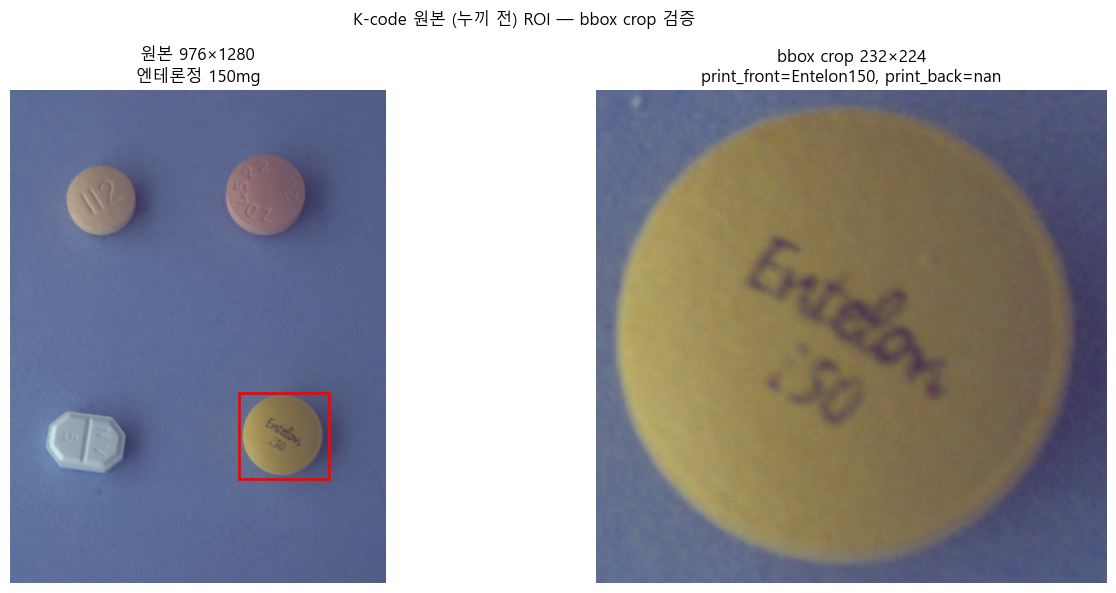


저장: D:\pill_detection\analysis\figures\kcode_01_bbox_crop_check.png


In [4]:
import matplotlib.patches as patches
## 셀 4 — clean_df NaN 패턴 + bbox crop 1건 실측 (출력만)

# ============================================================
# 1) clean_df NaN 패턴 — image_exists NaN 인 733행이 어떤 행인지
# ============================================================
print("[1] clean_df NaN 행 패턴")
print("=" * 60)

nan_rows = df_clean[df_clean['image_exists'].isna()]
not_nan = df_clean[df_clean['image_exists'].notna()]
print(f"image_exists NaN: {len(nan_rows)}행")
print(f"image_exists notna: {len(not_nan)}행")

# NaN 행의 file_name 패턴
print(f"\nNaN 행 file_name 예시 5개:")
for fn in nan_rows['file_name'].head(5).tolist():
    print(f"  {fn}")

# NaN 행의 file_name 이 dataset_yolo 에 실제 존재하는지 표본 확인
DSY_TRAIN = ROOT / "data" / "dataset_yolo" / "images" / "train"
DSY_VAL = ROOT / "data" / "dataset_yolo" / "images" / "val"
sample_nan = nan_rows['file_name'].head(5).tolist()
print(f"\nNaN 행 파일이 dataset_yolo 에 실제 존재하는가:")
for fn in sample_nan:
    in_train = (DSY_TRAIN / fn).exists()
    in_val = (DSY_VAL / fn).exists()
    print(f"  {fn[:50]}... → train={in_train}, val={in_val}")


# ============================================================
# 2) file_name → 실제 경로 매핑 헬퍼
# ============================================================
def find_image_path(file_name):
    """dataset_yolo train/val 양쪽 검사. 둘 다 없으면 None."""
    p_train = DSY_TRAIN / file_name
    if p_train.exists():
        return p_train
    p_val = DSY_VAL / file_name
    if p_val.exists():
        return p_val
    return None


# 전체 매핑 검증 (시간 다소 소요)
print("\n" + "=" * 60)
print("[2] clean_df 전체 file_name → 이미지 경로 매핑 검증")
print("=" * 60)

found_train = 0
found_val = 0
not_found = 0
for fn in df_clean['file_name'].unique():  # unique 로 중복 제거 (한 이미지에 박스 여러개)
    p = find_image_path(fn)
    if p is None:
        not_found += 1
    elif 'train' in str(p):
        found_train += 1
    else:
        found_val += 1

n_unique = df_clean['file_name'].nunique()
print(f"clean_df unique file_name: {n_unique}")
print(f"  train 에서 발견: {found_train}")
print(f"  val 에서 발견: {found_val}")
print(f"  못 찾음: {not_found}")


# ============================================================
# 3) bbox crop 1건 실측 — 실제 어떻게 잘리는지 시각
# ============================================================
print("\n" + "=" * 60)
print("[3] bbox crop 1건 실측")
print("=" * 60)

# image_exists notna 인 행 중 무작위 1행
rng_pick = np.random.default_rng(2026)
pick_idx = rng_pick.integers(len(not_nan))
row = not_nan.iloc[pick_idx]
print(f"선택 행: {pick_idx}")
print(f"  file_name: {row['file_name']}")
print(f"  bbox: x={row['bbox_x']}, y={row['bbox_y']}, w={row['bbox_w']}, h={row['bbox_h']}")
print(f"  dl_name: {row['dl_name']}, class_idx: {row['class_idx']}")
print(f"  print_front: {row['print_front']}, print_back: {row['print_back']}")

img_path = find_image_path(row['file_name'])
print(f"  이미지 경로: {img_path}")
print(f"  존재: {img_path is not None and img_path.exists()}")

if img_path:
    img_bgr = imread_kr(img_path)
    print(f"  원본 shape: {img_bgr.shape}, dtype: {img_bgr.dtype}")
    
    # bbox crop (xywh → xyxy)
    x, y, w, h = int(row['bbox_x']), int(row['bbox_y']), int(row['bbox_w']), int(row['bbox_h'])
    crop_bgr = img_bgr[y:y+h, x:x+w]
    crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
    print(f"  crop shape: {crop_rgb.shape}")
    
    # 시각: 원본 이미지 + bbox / crop
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    axes[0].imshow(img_rgb)
    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='red', facecolor='none')
    axes[0].add_patch(rect)
    axes[0].set_title(f"원본 {img_rgb.shape[1]}×{img_rgb.shape[0]}\n{row['dl_name']}")
    axes[0].axis('off')
    
    axes[1].imshow(crop_rgb)
    axes[1].set_title(f"bbox crop {crop_rgb.shape[1]}×{crop_rgb.shape[0]}\n"
                      f"print_front={row['print_front']}, print_back={row['print_back']}")
    axes[1].axis('off')
    
    plt.suptitle("K-code 원본 (누끼 전) ROI — bbox crop 검증", fontsize=12)
    plt.tight_layout()
    
    out = FIG_DIR / "kcode_01_bbox_crop_check.png"
    plt.savefig(out, dpi=120, bbox_inches='tight')
    plt.show()
    print(f"\n저장: {out}")




## 4. 측정 방식 결정 — RGB bbox crop 직접 측정 (alpha 없음)

K-code 원본은 RGB (배경 포함, alpha 없음). 단계 2-B 의 measure 함수는 alpha 채널로 알약 영역 마스킹 후 lap 측정.

**선택**: bbox crop RGB 전체 영역에서 lap 측정 (alpha 없이).

**근거**:
- 측정 항목 3 (imgsz 다운샘플 보존) 은 "다운샘플 전후 같은 영역" 에서 lap 변화율을 보는 측정. base 가 같으면 보존율은 알약 영역 외 픽셀 포함 여부와 무관.
- 측정 항목 1 (각인 강도 절대값) 은 합성 ROI 와 절대값 직접 비교 부적절하나, 박제 인용 비교는 원칙 58 로 어차피 금지.
- 누끼 전후 비교 (측정 항목 2) 는 옵션 B (rembg) 시간 비용 측정 후 별도 결정.

**적용**:
- 단계 2-B 의 `measure_with_ksize` → alpha 제거 버전 `measure_kcode` 신규
- 알약 영역 = bbox crop 전체 (`alpha = np.ones_like`)
- ksize=3, percentile=90, ABS_THRESHOLD 는 이 노트북 내 K-code 풀로 재캘리브레이션

In [5]:
## 셀 6 — 측정 함수 정의 + ABS_THRESHOLD 캘리브레이션

# ── 측정 함수 (RGB crop 전체 영역 기준) ──
def measure_kcode(rgb, abs_threshold, ksize=3, percentile=90):
    """
    RGB crop 에서 imprint 측정.
    
    Returns:
        dict: pill_px, ratio_pct, ratio_abs, mean_lap, mask_pct, mask_abs, lap_abs
    """
    if rgb.ndim == 3 and rgb.shape[2] == 4:
        rgb = rgb[:, :, :3]
    
    h, w = rgb.shape[:2]
    pill_px = h * w
    
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_32F, ksize=ksize)
    lap_abs = np.abs(lap)
    
    pct_thr = np.percentile(lap_abs, percentile)
    mask_pct = lap_abs >= pct_thr
    mask_abs = lap_abs >= abs_threshold
    
    return {
        'pill_px': pill_px,
        'mask_pct': mask_pct,
        'ratio_pct': mask_pct.sum() / pill_px,
        'mask_abs': mask_abs,
        'ratio_abs': mask_abs.sum() / pill_px,
        'mean_lap': float(lap_abs[mask_pct].mean()) if mask_pct.any() else 0.0,
        'lap_abs': lap_abs,
    }


def measure_m2_kcode(rgb, scale, abs_threshold, ksize=3):
    """RGB crop → 다운샘플 → 원본 해상도 업샘플 → measure_kcode."""
    h, w = rgb.shape[:2]
    nw = max(1, int(round(w * scale)))
    nh = max(1, int(round(h * scale)))
    rgb_ds = cv2.resize(rgb, (nw, nh), interpolation=cv2.INTER_AREA)
    rgb_up = cv2.resize(rgb_ds, (w, h), interpolation=cv2.INTER_LINEAR)
    return measure_kcode(rgb_up, abs_threshold, ksize=ksize)


# ── 측정 풀 (image_exists notna 인 행만) ──
pool_df = df_clean[df_clean['image_exists'].notna()].reset_index(drop=True)
print(f"측정 풀: {len(pool_df)}행 (clean_df {len(df_clean)} 중 NaN 733 제외)")


# ── ABS_THRESHOLD 캘리브레이션: 50개 풀 ──
print("\n[ABS_THRESHOLD 캘리브레이션]")

SAMPLE_FOR_THRESHOLD = 50
SEED_THR = 123
rng_thr = np.random.default_rng(SEED_THR)
sample_indices = rng_thr.choice(len(pool_df), SAMPLE_FOR_THRESHOLD, replace=False)

all_imprint_lap_values = []
n_used = 0
for idx in sample_indices:
    row = pool_df.iloc[idx]
    img_path = find_image_path(row['file_name'])
    if img_path is None:
        continue
    img_bgr = imread_kr(img_path)
    if img_bgr is None:
        continue
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    x, y, w, h = int(row['bbox_x']), int(row['bbox_y']), int(row['bbox_w']), int(row['bbox_h'])
    crop = rgb[y:y+h, x:x+w]
    if crop.size == 0:
        continue
    
    m = measure_kcode(crop, abs_threshold=0, ksize=3, percentile=90)
    all_imprint_lap_values.extend(m['lap_abs'][m['mask_pct']].tolist())
    n_used += 1

ABS_THRESHOLD_KCODE = float(np.percentile(all_imprint_lap_values, 25))
print(f"  사용된 ROI: {n_used} / {SAMPLE_FOR_THRESHOLD}")
print(f"  imprint 픽셀 총 수: {len(all_imprint_lap_values):,}")
print(f"  lap_abs 25 percentile (= ABS_THRESHOLD_KCODE): {ABS_THRESHOLD_KCODE:.2f}")
print(f"  lap_abs median: {np.median(all_imprint_lap_values):.2f}")
print(f"  lap_abs mean: {np.mean(all_imprint_lap_values):.2f}")

측정 풀: 39131행 (clean_df 39864 중 NaN 733 제외)

[ABS_THRESHOLD 캘리브레이션]
  사용된 ROI: 50 / 50
  imprint 픽셀 총 수: 515,181
  lap_abs 25 percentile (= ABS_THRESHOLD_KCODE): 24.00
  lap_abs median: 28.00
  lap_abs mean: 31.07


## 5. K-code ROI 100개 × imgsz 측정

K-code 원본 ROI 100개에서 각인 강도 분포와 imgsz별 보존율 측정.

- 측정 방법: 다운샘플 후 원본 해상도로 업샘플 (M2), ksize=3
- 보존율 = (다운샘플 후 값) / (원본 값)
- 3개 지표: imprint 픽셀 비율 (`ratio_abs`), 절대 강도 (`mean_lap`), percentile 마스크 (`ratio_pct`)

In [6]:
## 셀 8 — 100 ROI × 3 imgsz 측정 (M2 방법)

# ── 다운샘플 scale 정의 ──
LONG_SIDE_ORIG = 1280
DOWNSAMPLE_TARGETS = {
    640: 640 / LONG_SIDE_ORIG,
    1024: 1024 / LONG_SIDE_ORIG,
    1280: 1280 / LONG_SIDE_ORIG,
}
print("imgsz별 scale:")
for imgsz, scale in DOWNSAMPLE_TARGETS.items():
    print(f"  {imgsz}: {scale:.4f}")


# ── 100 ROI 샘플링 ──
N_SAMPLE = 100
SEED_C = 2026
rng_c = np.random.default_rng(SEED_C)
sample_idx = rng_c.choice(len(pool_df), N_SAMPLE, replace=False)
print(f"\n[샘플링] 측정 풀 {len(pool_df)} 중 {N_SAMPLE}개 (seed={SEED_C})")


# ── 측정 ──
records = []
n_skipped = 0

for i, idx in enumerate(sample_idx):
    row = pool_df.iloc[idx]
    img_path = find_image_path(row['file_name'])
    if img_path is None:
        n_skipped += 1
        continue
    img_bgr = imread_kr(img_path)
    if img_bgr is None:
        n_skipped += 1
        continue
    rgb_full = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    x, y, w, h = int(row['bbox_x']), int(row['bbox_y']), int(row['bbox_w']), int(row['bbox_h'])
    crop = rgb_full[y:y+h, x:x+w]
    if crop.size == 0 or crop.shape[0] < 8 or crop.shape[1] < 8:
        n_skipped += 1
        continue
    
    # 원본 측정
    m_orig = measure_kcode(crop, ABS_THRESHOLD_KCODE, ksize=3)
    base_pct = m_orig['ratio_pct']
    base_abs = m_orig['ratio_abs']
    base_lap = m_orig['mean_lap']
    
    if base_lap == 0 or base_abs == 0:
        n_skipped += 1
        continue
    
    crop_h, crop_w = crop.shape[:2]
    crop_area = crop_w * crop_h
    
    # imgsz 별 측정
    for imgsz, scale in DOWNSAMPLE_TARGETS.items():
        m_ds = measure_m2_kcode(crop, scale, ABS_THRESHOLD_KCODE, ksize=3)
        records.append({
            'file_name': row['file_name'],
            'dl_name': row['dl_name'],
            'class_idx_clean': row.get('class_idx', np.nan),
            'crop_w': crop_w, 'crop_h': crop_h, 'crop_area': crop_area,
            'imgsz': imgsz,
            'orig_abs_%': base_abs * 100,
            'orig_lap': base_lap,
            'pct_pres_%': m_ds['ratio_pct']/base_pct*100 if base_pct>0 else 0,
            'abs_pres_%': m_ds['ratio_abs']/base_abs*100,
            'lap_pres_%': m_ds['mean_lap']/base_lap*100,
        })
    
    if (i+1) % 20 == 0:
        print(f"  {i+1}/{N_SAMPLE} 완료")

df_kcode = pd.DataFrame(records)
print(f"\n측정 완료: {len(df_kcode)}행 ({len(df_kcode)//3} ROI × 3 imgsz), 스킵 {n_skipped}건")


# ── imgsz별 보존율 분포 ──
print("\n[imgsz별 보존율 분포]")
print(f"{'imgsz':>6} | {'metric':>10} | {'mean':>7} {'median':>7} {'std':>6} | "
      f"{'p25':>6} {'p75':>6} | {'min':>6} {'max':>6}")
print("-" * 88)
for imgsz in DOWNSAMPLE_TARGETS:
    sub = df_kcode[df_kcode['imgsz']==imgsz]
    for metric, col in [('abs_pres', 'abs_pres_%'), ('lap_pres', 'lap_pres_%'), ('pct_pres', 'pct_pres_%')]:
        vals = sub[col]
        print(f"{imgsz:>6} | {metric:>10} | "
              f"{vals.mean():>7.1f} {vals.median():>7.1f} {vals.std():>6.1f} | "
              f"{vals.quantile(.25):>6.1f} {vals.quantile(.75):>6.1f} | "
              f"{vals.min():>6.1f} {vals.max():>6.1f}")
    print()


# ── 페어 비교 (같은 ROI 에서 imgsz 차이) ──
print("[페어 비교 — 같은 ROI에서 imgsz 차이]")
piv_lap = df_kcode.pivot(index='file_name', columns='imgsz', values='lap_pres_%')
piv_abs = df_kcode.pivot(index='file_name', columns='imgsz', values='abs_pres_%')

diff_lap_640_1024 = piv_lap[1024] - piv_lap[640]
diff_lap_1024_1280 = piv_lap[1280] - piv_lap[1024]
diff_abs_640_1024 = piv_abs[1024] - piv_abs[640]
diff_abs_1024_1280 = piv_abs[1280] - piv_abs[1024]

print(f"  lap_pres: 1024 -  640 = mean {diff_lap_640_1024.mean():.1f}, median {diff_lap_640_1024.median():.1f}")
print(f"  lap_pres: 1280 - 1024 = mean {diff_lap_1024_1280.mean():.1f}, median {diff_lap_1024_1280.median():.1f}")
print(f"  abs_pres: 1024 -  640 = mean {diff_abs_640_1024.mean():.1f}, median {diff_abs_640_1024.median():.1f}")
print(f"  abs_pres: 1280 - 1024 = mean {diff_abs_1024_1280.mean():.1f}, median {diff_abs_1024_1280.median():.1f}")


# ── 원본 ROI imprint 강도 분포 (측정 항목 1) ──
print("\n[원본 ROI imprint 강도 분포 — 100 ROI]")
orig_only = df_kcode[df_kcode['imgsz']==640][['orig_abs_%', 'orig_lap', 'crop_w', 'crop_h', 'crop_area']]
print(f"  ratio_abs (%): mean {orig_only['orig_abs_%'].mean():.2f}, "
      f"median {orig_only['orig_abs_%'].median():.2f}, "
      f"std {orig_only['orig_abs_%'].std():.2f}")
print(f"  mean_lap     : mean {orig_only['orig_lap'].mean():.2f}, "
      f"median {orig_only['orig_lap'].median():.2f}, "
      f"std {orig_only['orig_lap'].std():.2f}")
print(f"  crop area    : mean {orig_only['crop_area'].mean():.0f}, "
      f"median {orig_only['crop_area'].median():.0f}")
print(f"  crop w×h     : mean {orig_only['crop_w'].mean():.0f} × {orig_only['crop_h'].mean():.0f}")

imgsz별 scale:
  640: 0.5000
  1024: 0.8000
  1280: 1.0000

[샘플링] 측정 풀 39131 중 100개 (seed=2026)
  20/100 완료
  40/100 완료
  60/100 완료
  80/100 완료
  100/100 완료

측정 완료: 300행 (100 ROI × 3 imgsz), 스킵 0건

[imgsz별 보존율 분포]
 imgsz |     metric |    mean  median    std |    p25    p75 |    min    max
----------------------------------------------------------------------------------------
   640 |   abs_pres |    10.2     8.0   10.6 |    1.3   13.8 |    0.0   44.3
   640 |   lap_pres |    41.2    40.3    7.0 |   35.2   47.0 |   29.5   56.3
   640 |   pct_pres |   123.7   120.0   22.4 |  105.0  142.3 |   85.5  175.6

  1024 |   abs_pres |    19.0    17.6   12.1 |    8.6   25.1 |    3.3   51.9
  1024 |   lap_pres |    55.3    54.8    5.9 |   50.1   60.0 |   45.6   68.9
  1024 |   pct_pres |   114.4   113.6   15.5 |  104.5  123.6 |   83.1  158.4

  1280 |   abs_pres |   100.0   100.0    0.0 |  100.0  100.0 |  100.0  100.0
  1280 |   lap_pres |   100.0   100.0    0.0 |  100.0  100.0 |  100.0  100.0
  1

## 6. 시각화 — boxplot + ROI 크기 vs 보존율

C:\Users\tran6\AppData\Local\Temp\ipykernel_7136\2039970026.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],
C:\Users\tran6\AppData\Local\Temp\ipykernel_7136\2039970026.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],
C:\Users\tran6\AppData\Local\Temp\ipykernel_7136\2039970026.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],


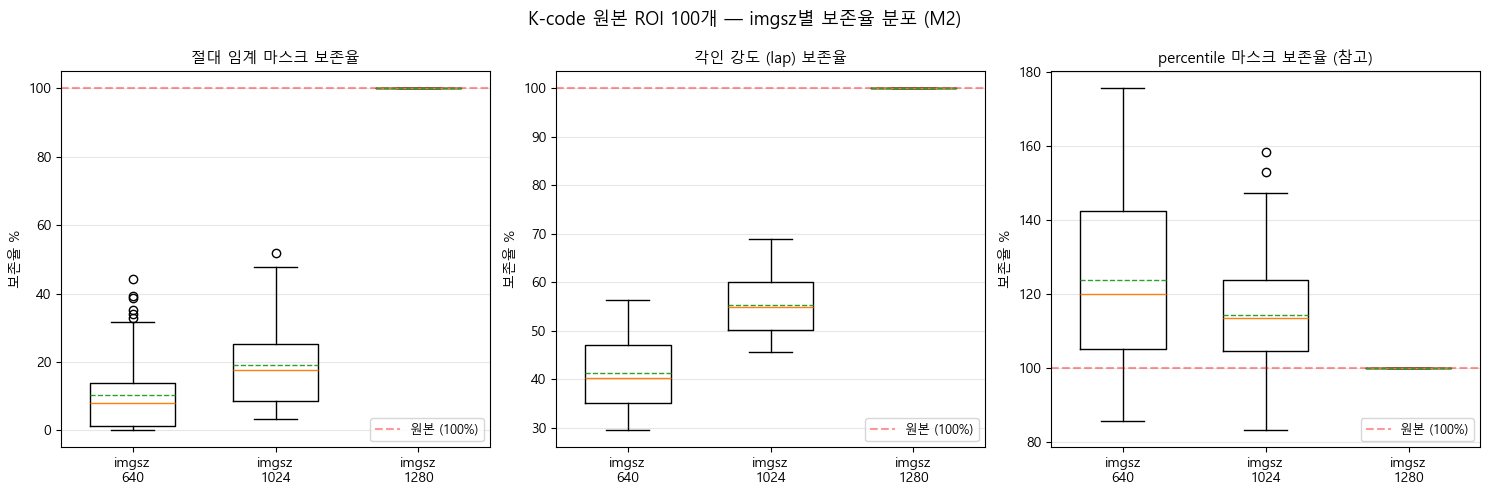

저장: D:\pill_detection\analysis\figures\kcode_02_100roi_distribution.png


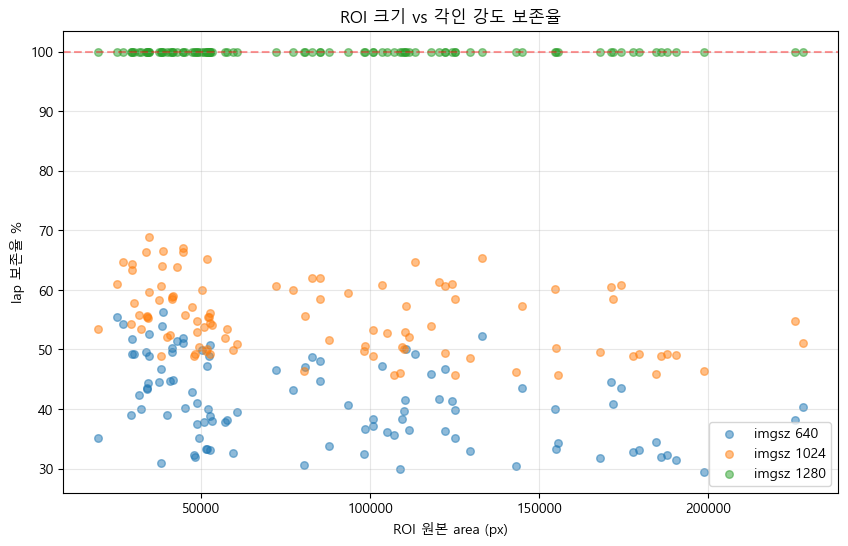

저장: D:\pill_detection\analysis\figures\kcode_03_area_vs_preservation.png


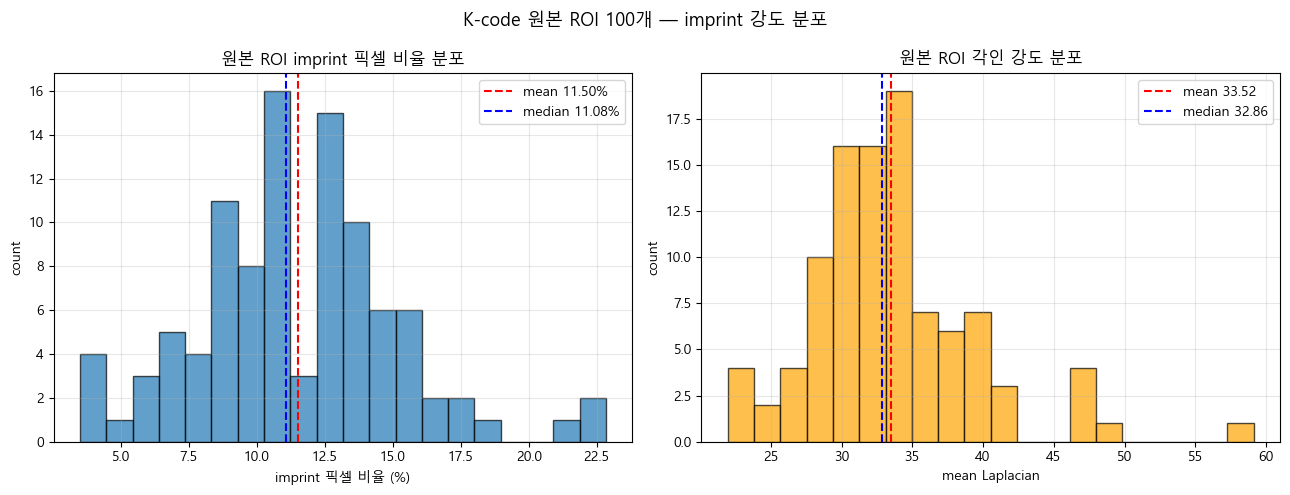

저장: D:\pill_detection\analysis\figures\kcode_04_imprint_intensity_dist.png


In [7]:
## 셀 10 — 시각화 (boxplot 3개 + area vs preservation scatter)

# ── boxplot 3개 (abs / lap / pct) ──
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = [
    ('abs_pres_%', '절대 임계 마스크 보존율'),
    ('lap_pres_%', '각인 강도 (lap) 보존율'),
    ('pct_pres_%', 'percentile 마스크 보존율 (참고)'),
]
for ax, (col, title) in zip(axes, metrics):
    data = [df_kcode[df_kcode['imgsz']==sz][col].values for sz in DOWNSAMPLE_TARGETS]
    bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],
                    showmeans=True, meanline=True, widths=0.6)
    ax.axhline(100, color='red', linestyle='--', alpha=0.4, label='원본 (100%)')
    ax.set_title(title, fontsize=11)
    ax.set_ylabel('보존율 %')
    ax.grid(alpha=0.3, axis='y')
    ax.legend(loc='lower right', fontsize=9)

plt.suptitle(f"K-code 원본 ROI 100개 — imgsz별 보존율 분포 (M2)", fontsize=13)
plt.tight_layout()

out = FIG_DIR / "kcode_02_100roi_distribution.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out}")


# ── ROI 크기 vs lap_pres scatter ──
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
for imgsz in DOWNSAMPLE_TARGETS:
    sub = df_kcode[df_kcode['imgsz']==imgsz]
    ax.scatter(sub['crop_area'], sub['lap_pres_%'], alpha=0.5, label=f'imgsz {imgsz}', s=30)
ax.axhline(100, color='red', linestyle='--', alpha=0.4)
ax.set_xlabel('ROI 원본 area (px)')
ax.set_ylabel('lap 보존율 %')
ax.set_title('ROI 크기 vs 각인 강도 보존율')
ax.legend()
ax.grid(alpha=0.3)

out2 = FIG_DIR / "kcode_03_area_vs_preservation.png"
plt.savefig(out2, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out2}")


# ── 원본 ROI imprint 강도 분포 (측정 항목 1) ──
orig_only = df_kcode[df_kcode['imgsz']==640][['orig_abs_%', 'orig_lap', 'crop_area']]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(orig_only['orig_abs_%'], bins=20, edgecolor='black', alpha=0.7)
axes[0].axvline(orig_only['orig_abs_%'].mean(), color='red', linestyle='--', label=f"mean {orig_only['orig_abs_%'].mean():.2f}%")
axes[0].axvline(orig_only['orig_abs_%'].median(), color='blue', linestyle='--', label=f"median {orig_only['orig_abs_%'].median():.2f}%")
axes[0].set_xlabel('imprint 픽셀 비율 (%)')
axes[0].set_ylabel('count')
axes[0].set_title('원본 ROI imprint 픽셀 비율 분포')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(orig_only['orig_lap'], bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[1].axvline(orig_only['orig_lap'].mean(), color='red', linestyle='--', label=f"mean {orig_only['orig_lap'].mean():.2f}")
axes[1].axvline(orig_only['orig_lap'].median(), color='blue', linestyle='--', label=f"median {orig_only['orig_lap'].median():.2f}")
axes[1].set_xlabel('mean Laplacian')
axes[1].set_ylabel('count')
axes[1].set_title('원본 ROI 각인 강도 분포')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('K-code 원본 ROI 100개 — imprint 강도 분포', fontsize=13)
plt.tight_layout()

out3 = FIG_DIR / "kcode_04_imprint_intensity_dist.png"
plt.savefig(out3, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out3}")

## 7. rembg 누끼 처리 전후 각인 보존 비교

### 측정 환경

본 측정은 Colab 에서 진행 (로컬 venv 는 rembg 정본 호환 환경 구성 어려움).

- 모델: `isnet-general-use` (합성 코드 `synthetic_images.py` 와 동일)
- alpha 검증: alpha>128 비율 ≥ 0.35 (합성 코드 기준)
- 누끼 후 측정: alpha 채널 마스킹 + 외곽 침식 2회 후 lap 측정
- 누끼 전 측정: bbox crop RGB 전체 영역
- 100 ROI (sample_idx seed=2026, 측정 항목 1·3 과 동일 풀)

### 결과 파일

`D:\pill_detection\analysis\kcode_rembg_results.csv` (Drive `pill_detection_3팀/seungwon/analysis/` 에서 다운로드).

[로드] D:\pill_detection\analysis\kcode_rembg_results.csv
  shape: (100, 15)
  columns: ['file_name', 'dl_name', 'crop_w', 'crop_h', 'crop_area', 'rembg_seconds', 'alpha_ratio', 'is_valid_crop', 'pre_pill_px', 'pre_ratio_abs_%', 'pre_mean_lap', 'post_pill_px', 'post_ratio_abs_%', 'post_mean_lap', 'lap_pres_%']

[누끼 전후 측정값 분포]
              metric |     mean   median     std
------------------------------------------------------------
    누끼 전 ratio_abs % |    11.50    11.08    3.73
    누끼 후 ratio_abs % |     8.29     8.58    5.17
       누끼 전 mean_lap |    33.52    32.86    5.93
       누끼 후 mean_lap |    27.91    28.75    8.60
lap 보존율 % (post/pre) |    83.53    88.31   22.36

alpha < 0.35 (invalid_crop): 7 / 100건

rembg 처리 시간: mean 3.75초/ROI, median 3.39초


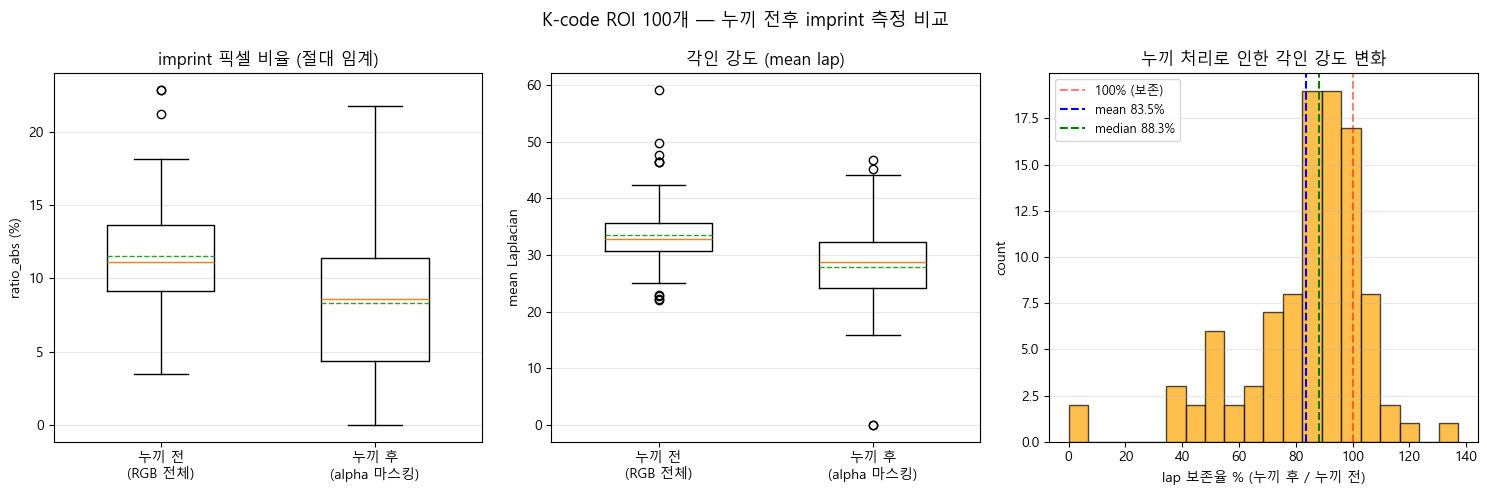

저장: D:\pill_detection\analysis\figures\kcode_06_rembg_pre_vs_post.png


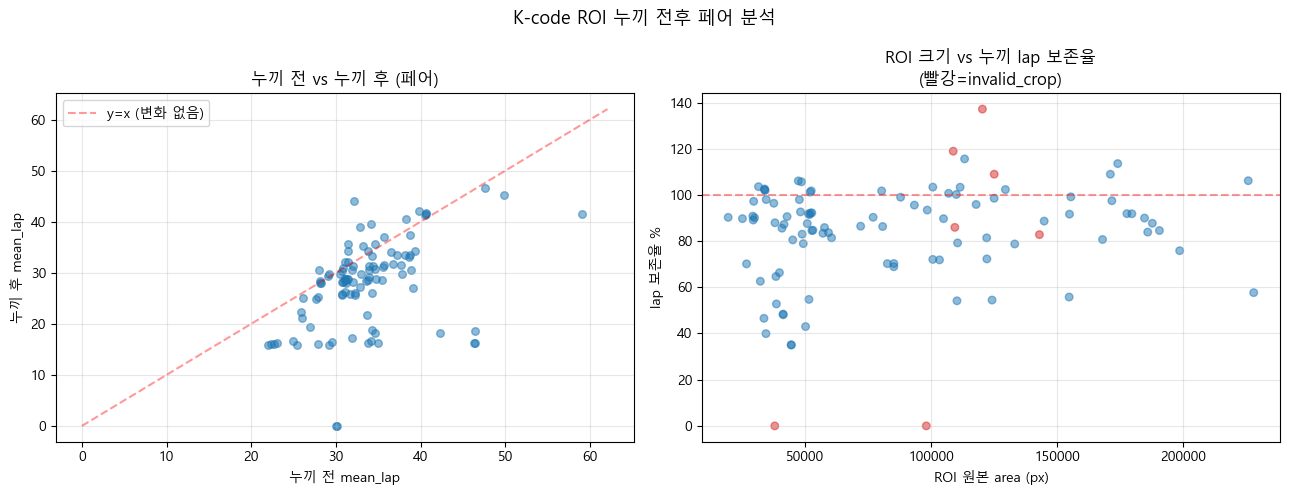

저장: D:\pill_detection\analysis\figures\kcode_07_rembg_pair_scatter.png

[invalid_crop 7건 — alpha 비율 낮은 순]
                                           file_name            dl_name  crop_w  crop_h  alpha_ratio  lap_pres_%
       K-005391-013900-016688_0_2_0_2_75_000_200.png              프로스카정     204     186     0.000000    0.000000
K-010487-026993-035659-044266_0_2_0_2_75_000_200.png  동화덴스톨캡슐 150mg/PTP     223     440     0.000815    0.000000
K-012638-023319-035659-043233_0_2_0_2_90_000_200.png  투스딘골드캡슐 150mg/PTP     235     463     0.005367  118.927696
K-000573-005094-013161-022627_0_2_0_2_90_000_200.png     엘스테인캡슐(에르도스테인)     254     474     0.249635  137.158289
K-005002-005094-012081-023223_0_2_0_2_70_000_200.png 엘도스캡슐(에르도스테인)(수출용)     265     472     0.279389  108.976458
K-012638-019881-029711-043233_0_2_0_2_90_000_200.png  투스딘골드캡슐 150mg/PTP     417     343     0.317658   82.808827
K-004378-019552-025438-037777_0_2_0_2_70_000_200.png    알바스테인캡슐(에르도스테인)     228     480     0.340515   

In [9]:
## 셀 — Colab 측정 결과 csv 로드 + 시각화 재현

CSV_PATH = ROOT / "analysis" / "kcode_rembg_results.csv"
df_rembg = pd.read_csv(CSV_PATH)

print(f"[로드] {CSV_PATH}")
print(f"  shape: {df_rembg.shape}")
print(f"  columns: {list(df_rembg.columns)}")


# ── 통계 출력 ──
print("\n[누끼 전후 측정값 분포]")
print(f"{'metric':>20} | {'mean':>8} {'median':>8} {'std':>7}")
print("-" * 60)
for label, col in [
    ('누끼 전 ratio_abs %', 'pre_ratio_abs_%'),
    ('누끼 후 ratio_abs %', 'post_ratio_abs_%'),
    ('누끼 전 mean_lap', 'pre_mean_lap'),
    ('누끼 후 mean_lap', 'post_mean_lap'),
    ('lap 보존율 % (post/pre)', 'lap_pres_%'),
]:
    vals = df_rembg[col]
    print(f"{label:>20} | {vals.mean():>8.2f} {vals.median():>8.2f} {vals.std():>7.2f}")

print(f"\nalpha < 0.35 (invalid_crop): "
      f"{(~df_rembg['is_valid_crop']).sum()} / {len(df_rembg)}건")
print(f"\nrembg 처리 시간: mean {df_rembg['rembg_seconds'].mean():.2f}초/ROI, "
      f"median {df_rembg['rembg_seconds'].median():.2f}초")


# ── 시각화 1: 누끼 전후 비교 boxplot + 보존율 히스토그램 ──
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

data_abs = [df_rembg['pre_ratio_abs_%'].values, df_rembg['post_ratio_abs_%'].values]
axes[0].boxplot(data_abs, tick_labels=['누끼 전\n(RGB 전체)', '누끼 후\n(alpha 마스킹)'],
                showmeans=True, meanline=True, widths=0.5)
axes[0].set_ylabel('ratio_abs (%)')
axes[0].set_title('imprint 픽셀 비율 (절대 임계)')
axes[0].grid(alpha=0.3, axis='y')

data_lap = [df_rembg['pre_mean_lap'].values, df_rembg['post_mean_lap'].values]
axes[1].boxplot(data_lap, tick_labels=['누끼 전\n(RGB 전체)', '누끼 후\n(alpha 마스킹)'],
                showmeans=True, meanline=True, widths=0.5)
axes[1].set_ylabel('mean Laplacian')
axes[1].set_title('각인 강도 (mean lap)')
axes[1].grid(alpha=0.3, axis='y')

axes[2].hist(df_rembg['lap_pres_%'], bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[2].axvline(100, color='red', linestyle='--', alpha=0.5, label='100% (보존)')
axes[2].axvline(df_rembg['lap_pres_%'].mean(), color='blue', linestyle='--',
                label=f"mean {df_rembg['lap_pres_%'].mean():.1f}%")
axes[2].axvline(df_rembg['lap_pres_%'].median(), color='green', linestyle='--',
                label=f"median {df_rembg['lap_pres_%'].median():.1f}%")
axes[2].set_xlabel('lap 보존율 % (누끼 후 / 누끼 전)')
axes[2].set_ylabel('count')
axes[2].set_title('누끼 처리로 인한 각인 강도 변화')
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3, axis='y')

plt.suptitle('K-code ROI 100개 — 누끼 전후 imprint 측정 비교', fontsize=13)
plt.tight_layout()

out = FIG_DIR / 'kcode_06_rembg_pre_vs_post.png'
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out}")


# ── 시각화 2: 페어 scatter ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(df_rembg['pre_mean_lap'], df_rembg['post_mean_lap'], alpha=0.5, s=30)
xy_max = max(df_rembg['pre_mean_lap'].max(), df_rembg['post_mean_lap'].max()) * 1.05
axes[0].plot([0, xy_max], [0, xy_max], 'r--', alpha=0.4, label='y=x (변화 없음)')
axes[0].set_xlabel('누끼 전 mean_lap')
axes[0].set_ylabel('누끼 후 mean_lap')
axes[0].set_title('누끼 전 vs 누끼 후 (페어)')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(df_rembg['crop_area'], df_rembg['lap_pres_%'],
                alpha=0.5, s=30,
                c=df_rembg['is_valid_crop'].map({True: 'tab:blue', False: 'tab:red'}))
axes[1].axhline(100, color='red', linestyle='--', alpha=0.4)
axes[1].set_xlabel('ROI 원본 area (px)')
axes[1].set_ylabel('lap 보존율 %')
axes[1].set_title('ROI 크기 vs 누끼 lap 보존율\n(빨강=invalid_crop)')
axes[1].grid(alpha=0.3)

plt.suptitle('K-code ROI 누끼 전후 페어 분석', fontsize=13)
plt.tight_layout()

out2 = FIG_DIR / 'kcode_07_rembg_pair_scatter.png'
plt.savefig(out2, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out2}")


# ── invalid_crop 7건 패턴 출력 ──
invalid = df_rembg[~df_rembg['is_valid_crop']].sort_values('alpha_ratio')
print(f"\n[invalid_crop 7건 — alpha 비율 낮은 순]")
print(invalid[['file_name', 'dl_name', 'crop_w', 'crop_h', 'alpha_ratio', 'lap_pres_%']].to_string(index=False))

## 8. 단계 2-D 측정 종합

### 측정 항목별 결과

| 측정 항목 | 핵심 결과 | figure |
|---|---|---|
| 1. K-code 원본 ROI 각인 강도 분포 | mean ratio_abs **11.50%**, mean_lap **33.52**, crop area 평균 261×312 | `kcode_04_imprint_intensity_dist.png` |
| 2. rembg 누끼 전후 비교 (lap 보존) | mean **83.5%**, median **88.3%**, std 22.4 | `kcode_06_rembg_pre_vs_post.png` |
| 2-1. invalid_crop (alpha < 0.35) | **7/100 (7%)**, 6건이 캡슐/PTP 형태 | `kcode_07_rembg_pair_scatter.png` |
| 3. K-code imgsz 다운샘플 보존 (M2) | 640: 41.2% / 1024: 55.3% / 1280: 100%. 1024→1280 페어 +44.7p | `kcode_02_100roi_distribution.png`, `kcode_03_area_vs_preservation.png` |

### 처방 영향

- **처방 1 (imgsz 1280)**: K-code 원본에서도 1024→1280 점프 명확 (+44.7p). 합성 ROI 측정과 일관된 결론. 처방 1 유지.
- **누끼 자체 손실**: lap 강도 평균 16.5% 손실 (post/pre = 83.5%). imgsz 와 무관한 base 손실. 합성 데이터 풀의 imprint 강도가 K-code 원본 대비 약 84% 수준에서 시작.
- **invalid_crop 캡슐 편향**: rembg `isnet-general-use` 가 캡슐/PTP 포장 형태에 약함. 합성 데이터 풀에 캡슐류 포함 비율이 K-code 원본보다 낮을 가능성. 클래스 다양성 검증 시 추가 확인 필요.

### (부수) 측정 항목 4 — GT 매칭 의심 8개 박스 검증

단계 2-C 에서 발견한 8개 박스 (conf 상위 50 시각 검토 시 "온전한 알약" 으로 분류된 것). 본 노트북 외 별도 셀에서 검증 예정.

### 측정 한계

1. K-code 원본 RGB 측정은 alpha 마스킹 없이 bbox crop 전체. 합성 ROI (RGBA + alpha 마스킹) 와 절대값 직접 비교 불가. 단 같은 ROI 내 변화율 측정은 일관됨.
2. rembg 측정 시 `isnet-general-use` 모델 사용. 합성 코드와 동일하지만 rembg 버전은 일치 보장 X (지우님 합성 환경 미지).
3. 처방 1 의 의미는 "현재 합성 환경에서 손실 없는 imgsz" — 1280 이 절대 정답이 아니라 1024 대비 의미 있는 점프가 1280 에서 발생한다는 것.

## 9. (부수) 단계 2-C GT 매칭 의심 8개 박스 시각 검증

단계 2-C `04_fp_classification.ipynb` 의 conf 상위 50 시각 검토에서 "온전한 알약" 으로 분류된 박스 약 8개. IoU<0.3 으로 FP_A 분류됐으나 시각상 알약을 정확히 잡은 것으로 보임. 가능한 원인:

- 라벨 누락 (해당 알약 GT 자체가 없음)
- 매칭 로직 문제 (IoU 계산 오류)
- NMS 실패 (Top-1 박스가 GT 와 매칭되지만 다른 박스가 같은 알약 위에 추가)
- 시각 분류 오인 (수동 검토) (실제론 일부만 잡은 박스)

### 검증 방법

1. 평가 JSON 다시 로드
2. FP_A 중 conf 상위 50 → 시각상 "온전한 알약" 8개 식별 (자동 식별 어려우므로 conf 상위 + ROI 형태 기준 유추)
3. 해당 이미지에서 GT 박스 + 의심 박스 함께 시각화
4. 각 박스 분류

In [10]:
## 셀 — 평가 JSON 재로드 + FP_A conf 상위 50 추출

EVAL_JSON_PATH = ROOT / "eval" / "rtmdet_tiny_synth_e15_seed100_results.json"
TEST_IMG_DIR = ROOT / "eval" / "test_images"
TEST_LBL_DIR = ROOT / "eval" / "test_labels" / "test_labels"

print(f"평가 JSON: {EVAL_JSON_PATH}")
print(f"  존재: {EVAL_JSON_PATH.exists()}")

with open(EVAL_JSON_PATH, "r", encoding="utf-8") as f:
    eval_data = json.load(f)

print(f"  results 길이: {len(eval_data['results'])}")


# IoU 함수 (단계 2-C 의 iou_xyxy 그대로)
def iou_xyxy(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    a1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    a2 = (box2[2]-box2[0]) * (box2[3]-box2[1])
    union = a1 + a2 - inter
    return inter / union if union > 0 else 0


# 모든 예측 박스 + 매칭 (단계 2-C 와 동일 로직)
records = []
for img_idx, r in enumerate(eval_data['results']):
    fname = r['filename']
    gts = r['gt_bboxes']
    preds = r['predictions']

    for pred_idx, p in enumerate(preds):
        pbox = p['bbox']
        top1_name = p['top3_class_name'][0]
        top1_conf = p['top3_confidence'][0]

        best_iou = 0.0
        best_gt_idx = -1
        best_gt_name = None
        for gi, g in enumerate(gts):
            iou = iou_xyxy(pbox, g['bbox'])
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gi
                best_gt_name = g['dl_name']

        if best_iou >= 0.5:
            category = 'TP' if top1_name == best_gt_name else 'FP_B_class'
        elif best_iou < 0.3:
            category = 'FP_A_loc'
        else:
            category = 'GRAY_03_05'
        if not gts:
            category = 'FP_A_loc'

        records.append({
            'img_idx': img_idx, 'filename': fname,
            'pbox': pbox,
            'top1_name': top1_name, 'top1_conf': top1_conf,
            'best_iou': best_iou,
            'best_gt_idx': best_gt_idx,
            'best_gt_name': best_gt_name,
            'category': category,
        })

df_pred = pd.DataFrame(records)
print(f"\n총 예측 박스: {len(df_pred)}")
print(f"카테고리 분포:")
print(df_pred['category'].value_counts())


# FP_A conf 상위 50
fp_a_top50 = df_pred[df_pred['category']=='FP_A_loc'].sort_values('top1_conf', ascending=False).head(50)
print(f"\nFP_A conf 상위 50: conf 범위 {fp_a_top50['top1_conf'].min():.3f} ~ {fp_a_top50['top1_conf'].max():.3f}")

평가 JSON: D:\pill_detection\eval\rtmdet_tiny_synth_e15_seed100_results.json
  존재: True
  results 길이: 33

총 예측 박스: 304
카테고리 분포:
category
FP_A_loc      250
FP_B_class     31
TP             14
GRAY_03_05      9
Name: count, dtype: int64

FP_A conf 상위 50: conf 범위 0.149 ~ 0.516


시각: FP_A conf 상위 50 (conf 0.149 ~ 0.516)


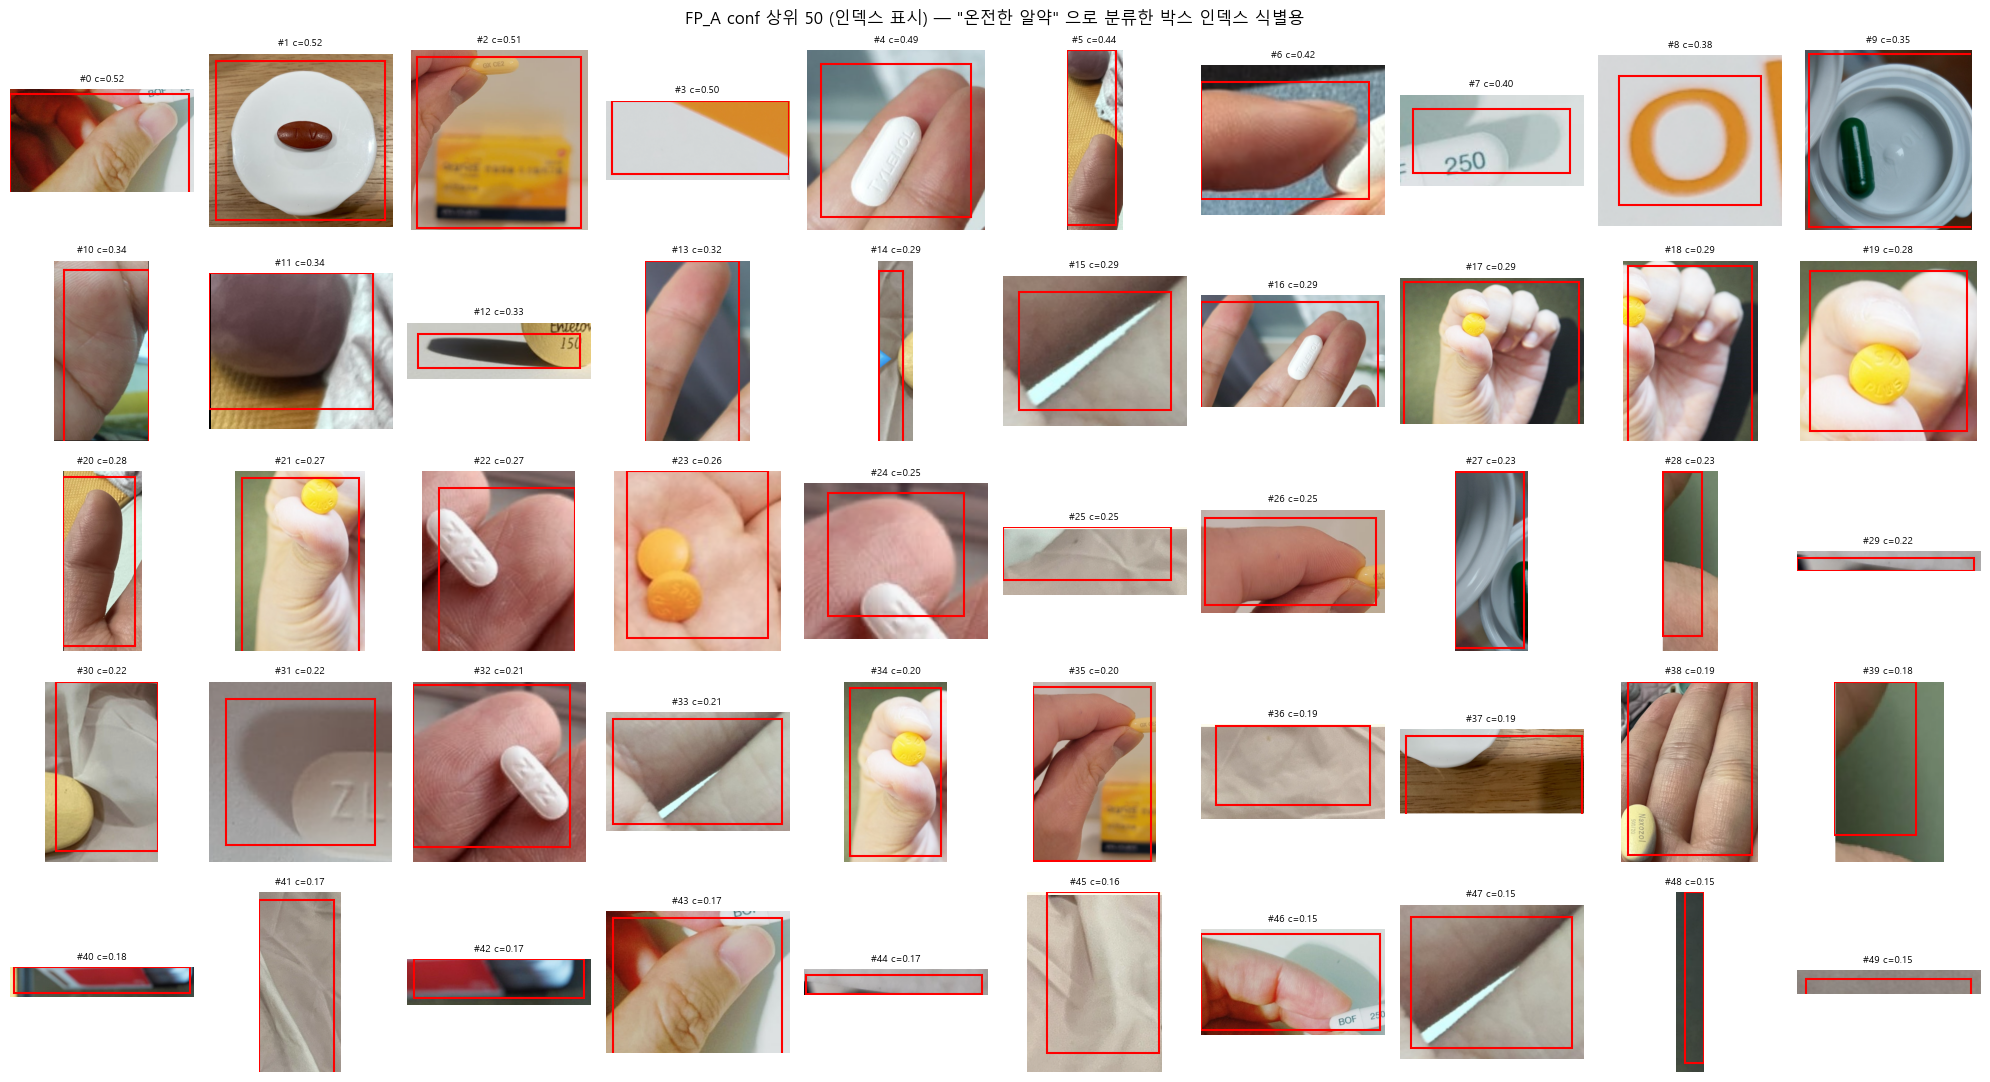


저장: D:\pill_detection\analysis\figures\fp_07_top50_with_index.png

각 박스의 #N 인덱스 확인 후, '온전한 알약' 으로 보이는 박스 번호 알려주시면 됩니다.


In [11]:
## 셀 — FP_A conf 상위 50 시각 (단계 2-C 와 동일, 인덱스 표시)

import matplotlib.patches as patches

# 이미지 캐시
img_cache = {}
for r in eval_data['results']:
    fname = r['filename']
    if fname not in img_cache:
        img_path = TEST_IMG_DIR / fname
        if img_path.exists():
            img_bgr = imread_kr(img_path)
            img_cache[fname] = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

fp_a_top50 = df_pred[df_pred['category']=='FP_A_loc'].sort_values('top1_conf', ascending=False).head(50).reset_index(drop=True)
print(f"시각: FP_A conf 상위 50 (conf {fp_a_top50['top1_conf'].min():.3f} ~ {fp_a_top50['top1_conf'].max():.3f})")


COLS = 10
ROWS = 5
N_SHOW = 50

fig, axes = plt.subplots(ROWS, COLS, figsize=(COLS*2, ROWS*2.2))

for i in range(N_SHOW):
    r = i // COLS
    c = i % COLS
    ax = axes[r, c]
    
    row = fp_a_top50.iloc[i]
    fname = row['filename']
    pbox = row['pbox']
    
    if fname not in img_cache:
        ax.axis('off')
        continue
    
    img = img_cache[fname]
    x1, y1, x2, y2 = [int(v) for v in pbox]
    
    # bbox 영역 + 약간 여유 padding
    pad = 20
    h, w = img.shape[:2]
    cx1 = max(0, x1 - pad)
    cy1 = max(0, y1 - pad)
    cx2 = min(w, x2 + pad)
    cy2 = min(h, y2 + pad)
    
    crop = img[cy1:cy2, cx1:cx2]
    ax.imshow(crop)
    
    # 박스 표시 (crop 좌표계로 변환)
    rect = patches.Rectangle((x1-cx1, y1-cy1), x2-x1, y2-y1,
                             linewidth=1.5, edgecolor='red', facecolor='none')
    ax.add_patch(rect)
    
    ax.set_title(f"#{i} c={row['top1_conf']:.2f}", fontsize=7)
    ax.axis('off')

# 50개 미만이면 나머지 빈 셀
for j in range(N_SHOW, ROWS*COLS):
    axes[j // COLS, j % COLS].axis('off')

plt.suptitle('FP_A conf 상위 50 (인덱스 표시) — "온전한 알약" 으로 분류한 박스 인덱스 식별용',
             fontsize=12)
plt.tight_layout()

out = FIG_DIR / "fp_07_top50_with_index.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n저장: {out}")
print(f"\n각 박스의 #N 인덱스 확인 후, '온전한 알약' 으로 보이는 박스 번호 알려주시면 됩니다.")

[의심 박스 9개]
  # 1 | 트루비타정 60mg.png                                     | top1=알마겔정(알마게이트)(수출명:유한가스트라겔정) c=0.516
  # 4 | 타이레놀500mg.png                                      | top1=    졸로푸트정 100mg c=0.490
  # 9 | 뮤테란캡슐 100mg.png                                    | top1=      디카맥스디플러스정 c=0.352
  #10 | 노바스크정 5mg.png                                      | top1=   람노스캡슐500mg/병 c=0.342
  #17 | 인사돌플러스정.png                                        | top1=          디카테오정 c=0.289
  #19 | 인사돌플러스정.png                                        | top1=     엔테론정 150mg c=0.285
  #23 | 인사돌플러스정 35mg_.png                                  | top1=이가탄에프캡슐 150mg/PTP c=0.260
  #32 | 지르텍정(세티리진염산염).png                                  | top1=  동아가바펜틴정 800mg c=0.208
  #34 | 인사돌플러스정.png                                        | top1=  씨즈날정(세티리진염산염) c=0.203


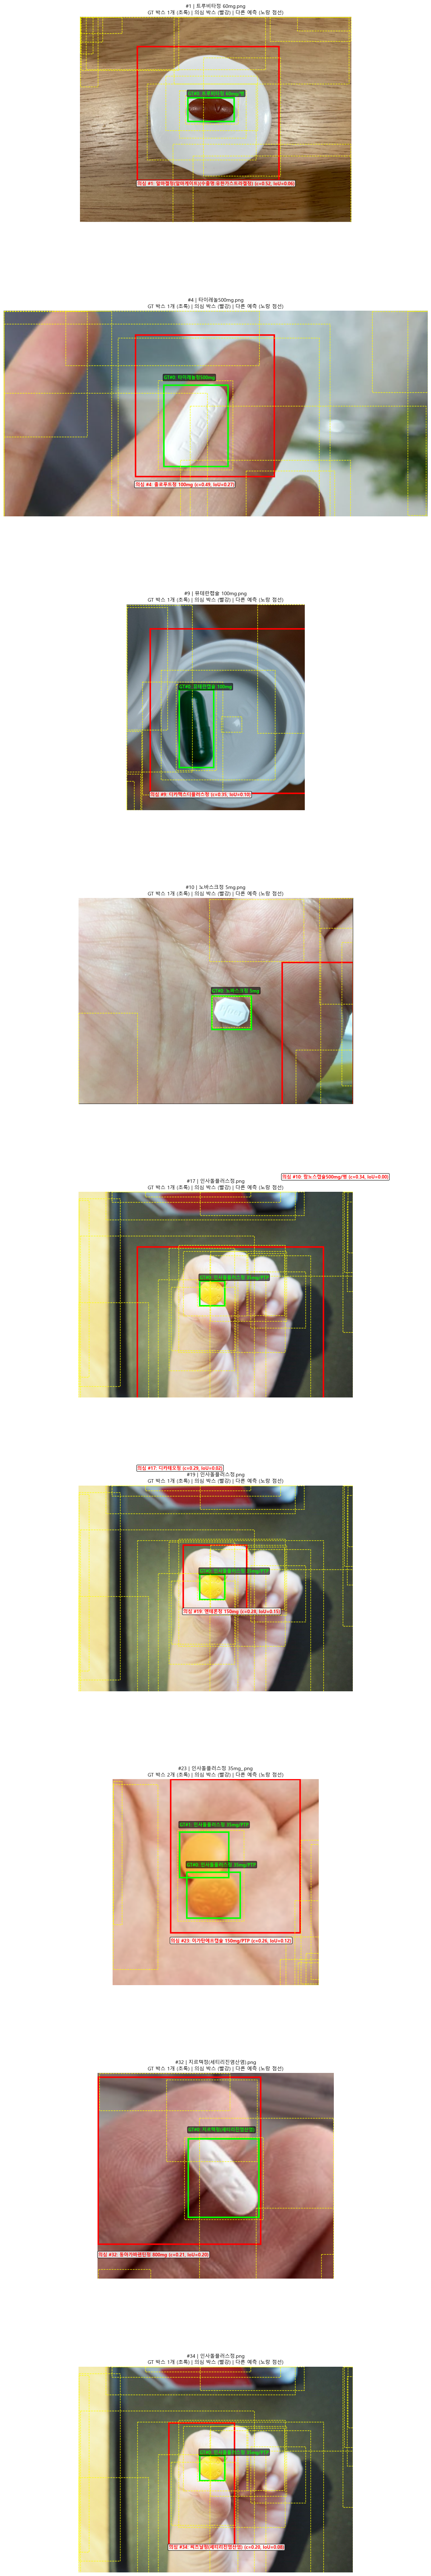


저장: D:\pill_detection\analysis\figures\fp_08_suspected_gt_check.png


In [12]:
## 셀 — 9개 의심 박스 GT 매칭 검증 (이미지 단위 전체 시각)

SUSPECTED_INDICES = [1, 4, 9, 10, 17, 19, 23, 32, 34]

# 9개 박스의 (filename, pbox, top1_name, top1_conf) 추출
suspected_rows = fp_a_top50.iloc[SUSPECTED_INDICES].copy().reset_index(drop=True)

print(f"[의심 박스 {len(suspected_rows)}개]")
for i, row in suspected_rows.iterrows():
    print(f"  #{SUSPECTED_INDICES[i]:>2} | {row['filename'][:50]:50s} | "
          f"top1={row['top1_name']:>15s} c={row['top1_conf']:.3f}")


# 각 박스가 속한 이미지에서 GT 박스 + 모든 예측 박스 같이 시각
N = len(suspected_rows)
fig, axes = plt.subplots(N, 1, figsize=(14, 8*N))
if N == 1:
    axes = [axes]

for ax_idx, (orig_idx, row) in enumerate(zip(SUSPECTED_INDICES, suspected_rows.itertuples(index=False))):
    fname = row.filename
    if fname not in img_cache:
        continue
    img = img_cache[fname]
    h, w = img.shape[:2]
    
    ax = axes[ax_idx]
    ax.imshow(img)
    
    # 해당 이미지의 GT 박스 (초록)
    img_data = next(r for r in eval_data['results'] if r['filename'] == fname)
    gts = img_data['gt_bboxes']
    for gi, g in enumerate(gts):
        gx1, gy1, gx2, gy2 = g['bbox']
        rect = patches.Rectangle((gx1, gy1), gx2-gx1, gy2-gy1,
                                 linewidth=3, edgecolor='lime', facecolor='none')
        ax.add_patch(rect)
        ax.text(gx1, gy1-10, f"GT#{gi}: {g['dl_name']}",
                color='lime', fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.6))
    
    # 의심 박스 (빨강, 굵게)
    px1, py1, px2, py2 = row.pbox
    rect = patches.Rectangle((px1, py1), px2-px1, py2-py1,
                             linewidth=3, edgecolor='red', facecolor='none')
    ax.add_patch(rect)
    ax.text(px1, py2+15, f"의심 #{orig_idx}: {row.top1_name} (c={row.top1_conf:.2f}, IoU={row.best_iou:.2f})",
            color='red', fontsize=9, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8))
    
    # 같은 이미지의 다른 모든 예측 박스 (노랑, 얇게) — NMS 실패 의심
    same_img_preds = df_pred[df_pred['filename'] == fname]
    for _, op in same_img_preds.iterrows():
        if list(op['pbox']) == list(row.pbox):
            continue  # 의심 박스 자체는 제외
        ox1, oy1, ox2, oy2 = op['pbox']
        rect = patches.Rectangle((ox1, oy1), ox2-ox1, oy2-oy1,
                                 linewidth=1, edgecolor='yellow', facecolor='none', linestyle='--')
        ax.add_patch(rect)
    
    ax.set_title(f"#{orig_idx} | {fname}\n"
                 f"GT 박스 {len(gts)}개 (초록) | 의심 박스 (빨강) | 다른 예측 (노랑 점선)",
                 fontsize=10)
    ax.axis('off')

plt.tight_layout()
out = FIG_DIR / "fp_08_suspected_gt_check.png"
plt.savefig(out, dpi=100, bbox_inches='tight')
plt.show()
print(f"\n저장: {out}")

## 9. (부수) GT 매칭 의심 박스 시각 검증 결과

단계 2-C `04_fp_classification.ipynb` 의 conf 상위 50 시각 검토에서 "온전한 알약" 으로 분류된 박스 9개 (#1, #4, #9, #10, #17, #19, #23, #32, #34) 검증.

### 검증 방법

각 박스가 속한 이미지에서 GT 박스 (초록) + 의심 박스 (빨강) + 다른 예측 박스 (노랑 점선) 함께 시각화.

### 결론

9개 박스 모두 **localization 부정확** 으로 FP_A 분류 정상.

| 패턴 | 개수 |
|---|---|
| GT 보다 훨씬 큰 영역 잡음 (배경 포함) | 5건 (#1, #4, #9, #23, #32) |
| GT 와 완전 다른 위치 인식 | 2건 (#10, #19) |
| 손가락 / 줄 패턴 잡음 | 2건 (#17, #34) |

작은 thumbnail 시각에서 알약 형태가 박스 안에 들어와 있어 "온전한 알약" 으로 보였으나, 전체 이미지 컨텍스트에서 보면 박스가 알약을 정확히 감싼 게 아님.

### 단계 2-C 박제값 영향

- "GT 매칭 의심 8개 박스 미해결" → **검증 완료, 의심 박스 모두 FP_A 분류 정상**
- TP recall 14/47 = 29.8% 박제값 그대로 유효
- 라벨 누락 / 매칭 로직 / NMS 실패 의심 → 모두 해소
- 처방 4 (배경 풀 재구성) 우선순위 / 구체 파라미터 변경 없음